In [2]:
import re
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
import requests

In [3]:
Brand=[]
Capacity=[]
Price=[]
Power_Rating=[]
RPM=[]
Discount=[]
Rating=[]
Load_type=[]


In [4]:
headers = {"User-Agent":"Mozilla/5.0"}
for i in range(1,11):
    url=f"https://www.flipkart.com/search?q=washing+machine&sid=j9e%2Cabm%2C8qx&as=on&as-show=on&otracker=AS_QueryStore_OrganicAutoSuggest_2_4_na_na_na&otracker1=AS_QueryStore_OrganicAutoSuggest_2_4_na_na_na&as-pos=2&as-type=RECENT&suggestionId=washing+machine%7CWashing+Machines&requestId=e2fc8b8a-ad50-4576-9d61-575df4ac5336&as-searchtext=washing+machine&page={i}"
    response = requests.get(url,headers=headers)
    soup = BeautifulSoup(response.content,"html.parser")


    name=soup.find_all("div",class_='RG5Slk')
    for i in name:
        text=i.text
        a=re.findall(r'^(.*?)\s+\d',text)
        Brand.extend(a)

    for i in soup.find_all("div",class_='RG5Slk'):
        text=i.text
        a=re.findall("(\d+\.\d|\d+)\skg",text)
        Capacity.extend(a)
        
    for i in soup.find_all("div",class_="hZ3P6w DeU9vF"):
        text=i.text
        a=re.findall(r'₹(.+)',text)
        Price.extend(a)

    star=soup.find_all("li",class_='DTBslk')
    for i in star:
        text=i.text
        a=re.findall(r'(\d+)\s+Star',text)
        Power_Rating.extend(a)

    rpm=soup.find_all("li",class_='DTBslk')
    for i in rpm:
        text=i.text
        a=re.findall(r'(\d+)\s*RPM', text, re.IGNORECASE)
        RPM.extend(a)
        
    for i in soup.find_all("span"):
        text=i.text
        a=re.findall(r'(\d+)\%\soff',text)
        Discount.extend(a)

    for i in soup.find_all('div',class_='MKiFS6'):
        text=i.text
        a=re.findall(r'\d\.\d',text)
        Rating.extend(a)

    for i in soup.find_all("div",class_='RG5Slk'):
        text=i.text
        a=re.findall(r'Top\sLoad|Front\sLoad',text)
        Load_type.extend(a)

In [5]:
# print(soup.prettify())

In [6]:
print(len(Brand),len(Capacity),len(Price),len(Power_Rating),len(RPM),len(Discount),len(Rating),len(Load_type))

240 238 240 237 240 290 281 170


In [7]:
from itertools import zip_longest

data = list(zip_longest(Brand,Capacity,Price,Power_Rating,RPM,Discount,Rating,Load_type))

data

[('IFB', '7', '27,990', '5', '1200', '22', '4.5', 'Top Load'),
 ('Voltas Beko', '9', '12,440', '5', '1350', '47', '4.3', 'Top Load'),
 ('realme TechLife', '7.5', '7,690', '5', '1350', '51', '4.2', 'Top Load'),
 ('FOXSKY', '6.5', '6,490', '5', '1300', '45', '3.9', 'Top Load'),
 ('Whirlpool', '7', '15,091', '5', '740', '22', '4.2', 'Top Load'),
 ('VW', '7.5', '7,399', '5', '1350', '61', '4.2', 'Top Load'),
 ('Samsung', '7', '17,490', '5', '700', '22', '4.3', 'Top Load'),
 ('Samsung', '10', '24,990', '5', '700', '26', '4.3', 'Top Load'),
 ('LG', '7', '11,490', '5', '1350', '29', '4.5', 'Top Load'),
 ('Midea', '6.5', '6,499', '5', '1350', '45', '4.2', 'Top Load'),
 ('Samsung', '8', '19,490', '5', '700', '27', '4.2', 'Top Load'),
 ('Voltas Beko', '6.5', '8,650', '5', '1350', '30', '4.3', 'Top Load'),
 ('realme TechLife', '7', '7,490', '5', '1400', '40', '4.2', 'Top Load'),
 ('Voltas Beko', '8.5', '11,790', '5', '1350', '48', '4.3', 'Top Load'),
 ('LG', '8', '19,987', '5', '740', '31', '4.4'

In [8]:
import pandas as pd

In [9]:
df=pd.DataFrame(data,columns=["Brand","Capacity","Price","Power_Rating","RPM","Discount","Rating","Load_type"])
df

,Brand,Capacity,Price,Power_Rating,RPM,Discount,Rating,Load_type
0,IFB,7,"27,990",5,1200,22,4.5,Top Load
1,Voltas Beko,9,"12,440",5,1350,47,4.3,Top Load
2,realme TechLife,7.5,"7,690",5,1350,51,4.2,Top Load
3,FOXSKY,6.5,"6,490",5,1300,45,3.9,Top Load
4,Whirlpool,7,"15,091",5,740,22,4.2,Top Load
...,...,...,...,...,...,...,...,...
285,None,None,None,None,None,22,None,None
286,None,None,None,None,None,19,None,None
287,None,None,None,None,None,23,None,None
288,None,None,None,None,None,21,None,None


# Data cleaning

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290 entries, 0 to 289
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Brand         240 non-null    object
 1   Capacity      238 non-null    object
 2   Price         240 non-null    object
 3   Power_Rating  237 non-null    object
 4   RPM           240 non-null    object
 5   Discount      290 non-null    object
 6   Rating        281 non-null    object
 7   Load_type     170 non-null    object
dtypes: object(8)
memory usage: 18.3+ KB


In [11]:
df=df.dropna()

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 170 entries, 0 to 169
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Brand         170 non-null    object
 1   Capacity      170 non-null    object
 2   Price         170 non-null    object
 3   Power_Rating  170 non-null    object
 4   RPM           170 non-null    object
 5   Discount      170 non-null    object
 6   Rating        170 non-null    object
 7   Load_type     170 non-null    object
dtypes: object(8)
memory usage: 12.0+ KB


In [13]:
df.shape

(170, 8)

In [14]:
df

,Brand,Capacity,Price,Power_Rating,RPM,Discount,Rating,Load_type
0,IFB,7,"27,990",5,1200,22,4.5,Top Load
1,Voltas Beko,9,"12,440",5,1350,47,4.3,Top Load
2,realme TechLife,7.5,"7,690",5,1350,51,4.2,Top Load
3,FOXSKY,6.5,"6,490",5,1300,45,3.9,Top Load
4,Whirlpool,7,"15,091",5,740,22,4.2,Top Load
...,...,...,...,...,...,...,...,...
165,Haier,8,"13,040",5,780,19,4.5,Front Load
166,IFB,7,"36,989",5,1200,22,4.4,Front Load
167,Samsung,9,"17,490",5,700,36,4.4,Top Load
168,realme TechLife,12,"10,290",5,1350,25,4.4,Top Load


In [15]:
df=df.astype({"Capacity":float,"Power_Rating":int,"RPM":int,"Discount":int,"Rating":float})

In [16]:
df

,Brand,Capacity,Price,Power_Rating,RPM,Discount,Rating,Load_type
0,IFB,7.0,"27,990",5,1200,22,4.5,Top Load
1,Voltas Beko,9.0,"12,440",5,1350,47,4.3,Top Load
2,realme TechLife,7.5,"7,690",5,1350,51,4.2,Top Load
3,FOXSKY,6.5,"6,490",5,1300,45,3.9,Top Load
4,Whirlpool,7.0,"15,091",5,740,22,4.2,Top Load
...,...,...,...,...,...,...,...,...
165,Haier,8.0,"13,040",5,780,19,4.5,Front Load
166,IFB,7.0,"36,989",5,1200,22,4.4,Front Load
167,Samsung,9.0,"17,490",5,700,36,4.4,Top Load
168,realme TechLife,12.0,"10,290",5,1350,25,4.4,Top Load


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 170 entries, 0 to 169
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         170 non-null    object 
 1   Capacity      170 non-null    float64
 2   Price         170 non-null    object 
 3   Power_Rating  170 non-null    int64  
 4   RPM           170 non-null    int64  
 5   Discount      170 non-null    int64  
 6   Rating        170 non-null    float64
 7   Load_type     170 non-null    object 
dtypes: float64(2), int64(3), object(3)
memory usage: 12.0+ KB


In [18]:
df["Price"] = df["Price"].str.replace(",", "").astype(int)

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 170 entries, 0 to 169
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         170 non-null    object 
 1   Capacity      170 non-null    float64
 2   Price         170 non-null    int64  
 3   Power_Rating  170 non-null    int64  
 4   RPM           170 non-null    int64  
 5   Discount      170 non-null    int64  
 6   Rating        170 non-null    float64
 7   Load_type     170 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 12.0+ KB


# Remove Duplicates

In [20]:
df=df.drop_duplicates()

In [21]:
df.shape

(166, 8)

In [22]:
df

,Brand,Capacity,Price,Power_Rating,RPM,Discount,Rating,Load_type
0,IFB,7.0,27990,5,1200,22,4.5,Top Load
1,Voltas Beko,9.0,12440,5,1350,47,4.3,Top Load
2,realme TechLife,7.5,7690,5,1350,51,4.2,Top Load
3,FOXSKY,6.5,6490,5,1300,45,3.9,Top Load
4,Whirlpool,7.0,15091,5,740,22,4.2,Top Load
...,...,...,...,...,...,...,...,...
164,Whirlpool,6.5,19990,5,740,46,4.4,Top Load
165,Haier,8.0,13040,5,780,19,4.5,Front Load
167,Samsung,9.0,17490,5,700,36,4.4,Top Load
168,realme TechLife,12.0,10290,5,1350,25,4.4,Top Load


In [23]:
import matplotlib.pyplot as py
import seaborn as sns

In [27]:
df['Brand'].value_counts()

Brand
realme TechLife                  52
Samsung                          24
Voltas Beko                      19
LG                               13
MOTOROLA                         12
Whirlpool                        11
FOXSKY                            9
Voltas Beko by A Tata Product     9
IFB                               7
Godrej                            5
Haier                             4
BOSCH                             4
Kenstar                           3
Uniboom                           2
Electrolux                        2
TCL                               2
Thomson                           2
InnoQ                             1
LG Electronics                    1
VW                                1
Midea                             1
ONIDA                             1
Lloyd                             1
Name: count, dtype: int64

# Univariant Analysis

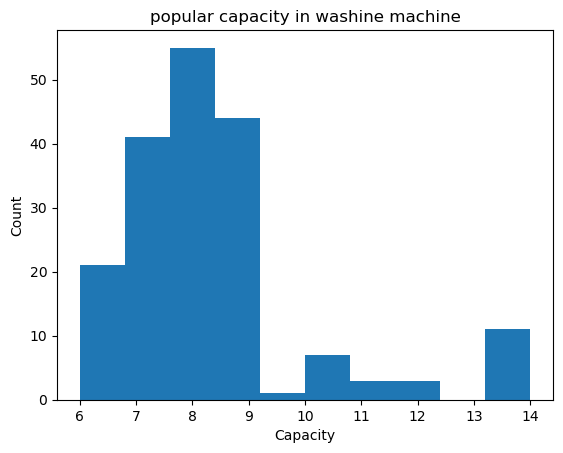

In [47]:
plt.hist(df["Capacity"])
plt.title("popular capacity in washine machine")
plt.xlabel("Capacity")
plt.ylabel("Count")
plt.show()

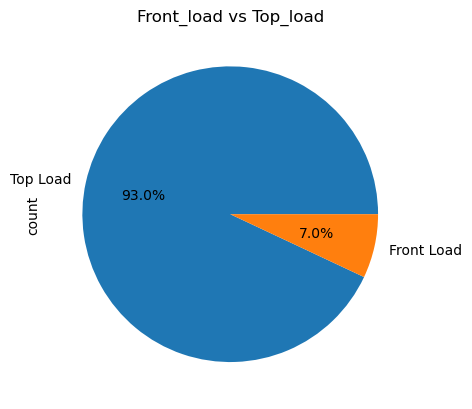

In [48]:
df["Load_type"].value_counts().plot(kind="pie",autopct="%1.1f%%")
plt.title("Front_load vs Top_load")
plt.show()

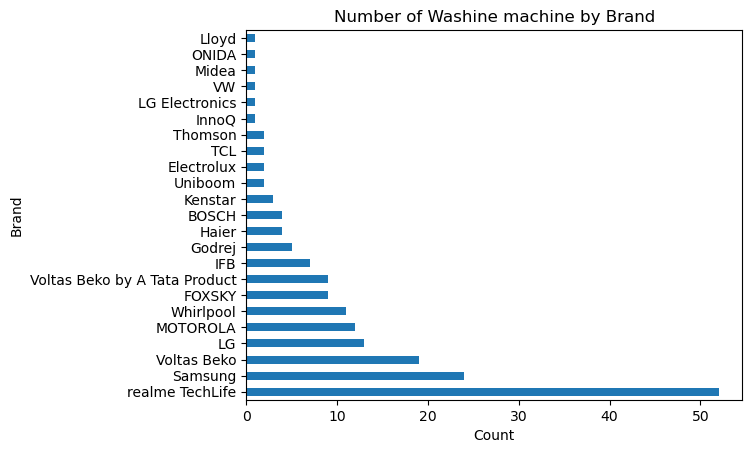

In [31]:
df['Brand'].value_counts().plot(kind='barh')
plt.title("Number of Washine machine by Brand")
plt.xlabel("Count")
plt.ylabel('Brand')
plt.show()

# Bivariant Analysis

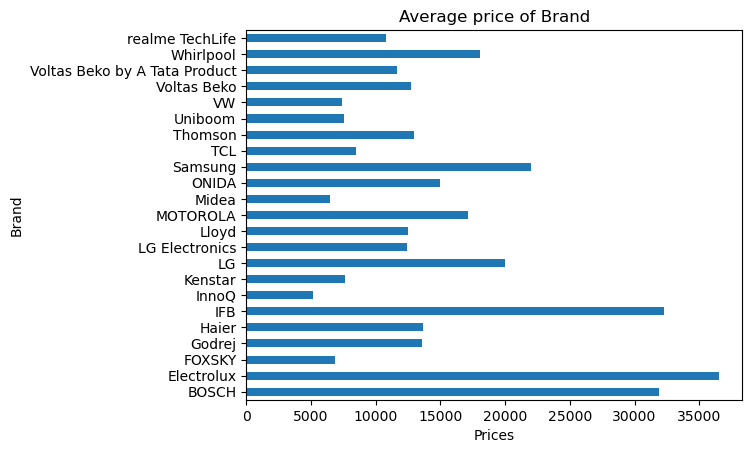

In [46]:
df.groupby("Brand")["Price"].mean().plot(kind="barh")
plt.title("Average price of Brand")
plt.xlabel("Prices")
plt.ylabel("Brand")
plt.show()

In [37]:
df.groupby("Power_Rating")["Price"].mean()

Power_Rating
5    15340.478495
Name: Price, dtype: float64

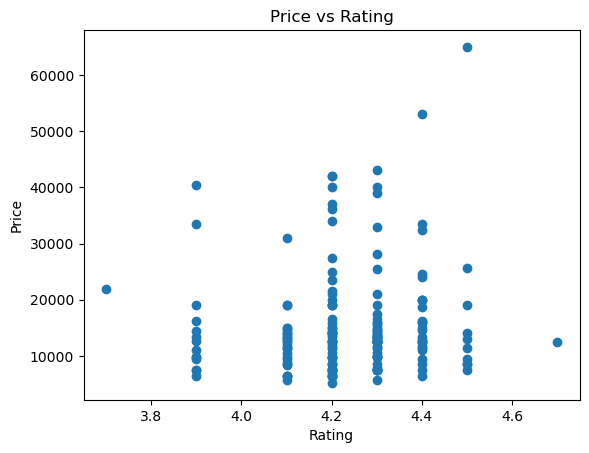

In [38]:
plt.scatter(df["Rating"],df["Price"])
plt.title("Price vs Rating")
plt.xlabel("Rating")
plt.ylabel("Price")
plt.show()

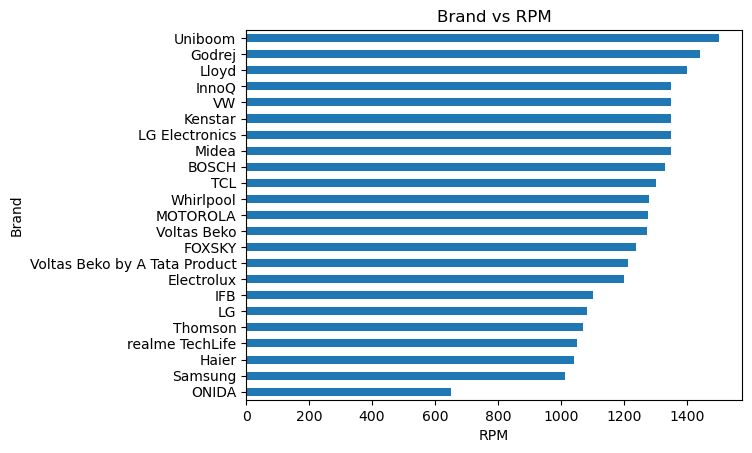

In [49]:
df.groupby("Brand")["RPM"].mean().sort_values().plot(
    kind="barh")
plt.title("Brand vs RPM")
plt.xlabel('RPM')
plt.ylabel("Brand")
plt.show()

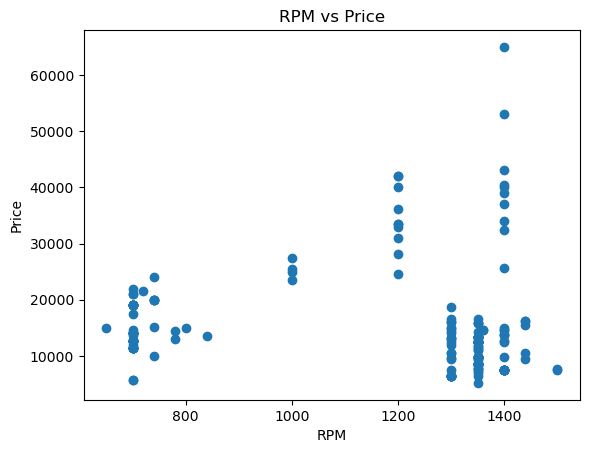

In [40]:
plt.scatter(df['RPM'],df['Price'])
plt.title("RPM vs Price")
plt.xlabel("RPM")
plt.ylabel("Price")
plt.show()

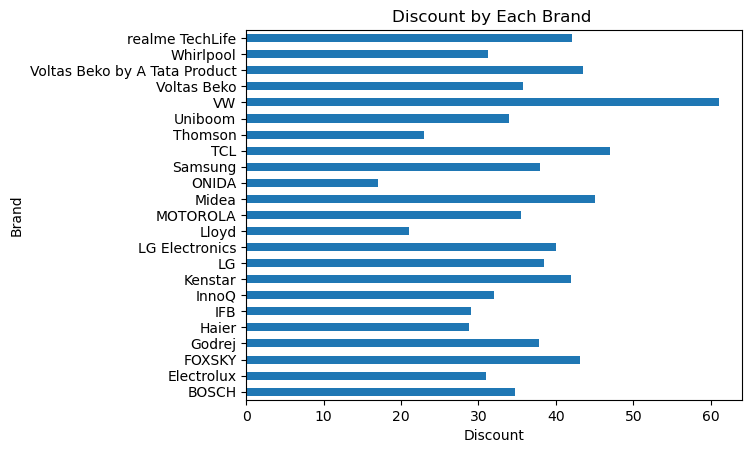

In [41]:
df.groupby('Brand')["Discount"].mean().plot(kind="barh")
plt.title("Discount by Each Brand ")
plt.xlabel("Discount")
plt.ylabel("Brand")
plt.show()

# Multi Variant Analysis

In [ ]:
numeric = ["Price","Capacity","RPM","Discount","Rating"]

df[numeric].corr()

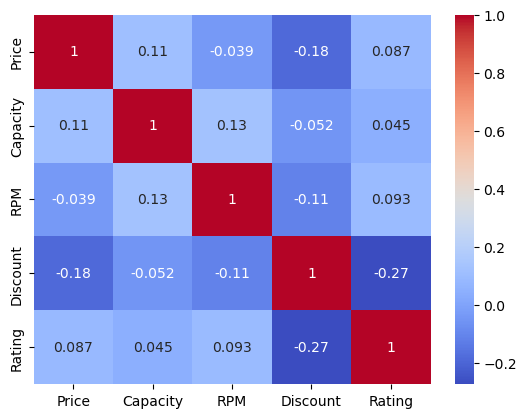

In [43]:
sns.heatmap(df[numeric].corr(),annot=True,cmap="coolwarm")
plt.show()

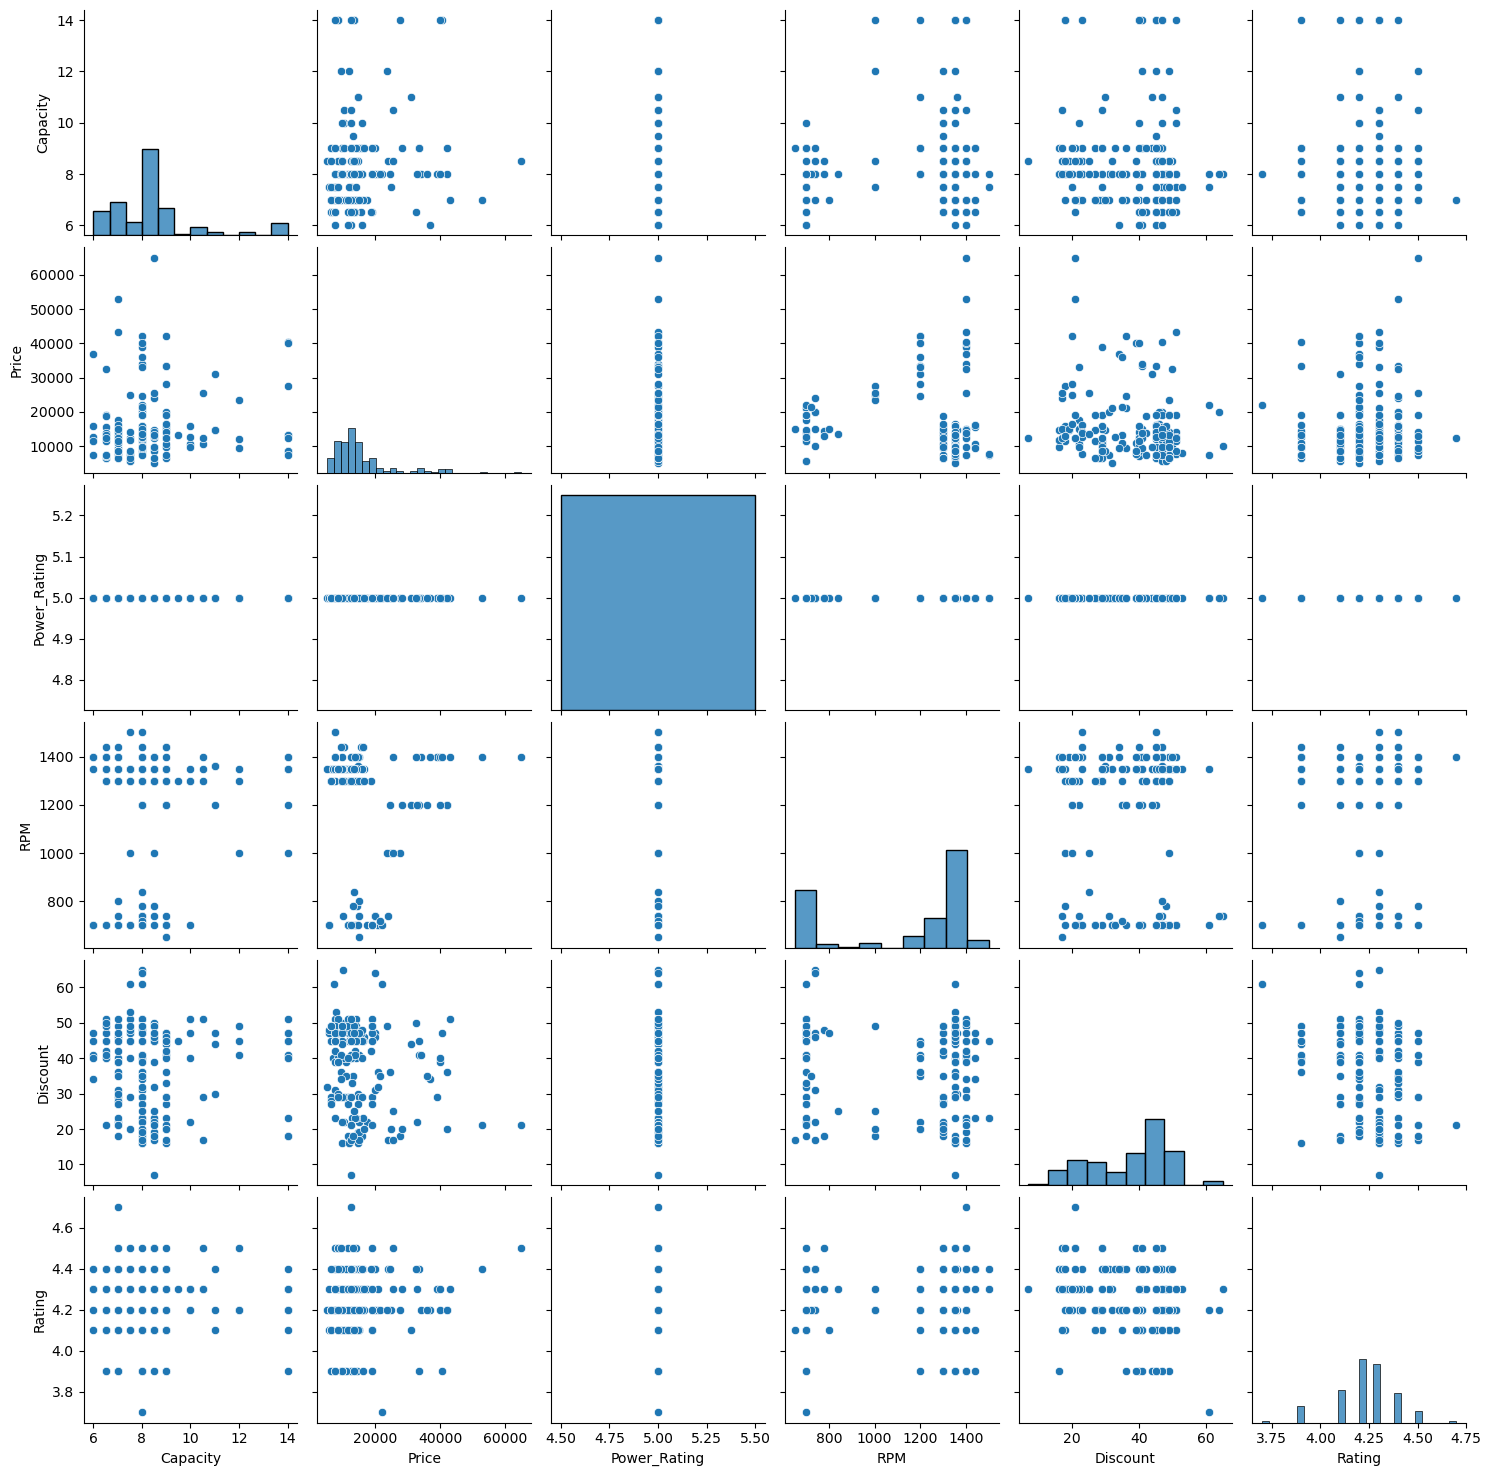

In [44]:
sns.pairplot(df)

# 1.Which brand has the largest number of washing machine models?
- Realme TechLife, Motorola, Samsung, Whirlpool, LG, Thomson, and Haier have the largest number of washing machine models in the dataset.
# 2.Which brand provides the highest average discount?
- InnoQ and Midea provide the highest average discounts among all the brands.
# 3.Is there a relationship between price and customer rating?
- There is no strong relationship between price and customer rating. Expensive washing machines do not always have higher ratings.
# 4.Does a higher RPM lead to a higher price?
- Yes. Washing machines with higher RPM generally have higher prices because they offer better spin performance and faster drying.
# 5.Which capacity is most common?
- The most common washing machine capacities in the dataset are 7 kg and 8 kg.
# 6.Which brands sell premium washing machines?
- IFB, Samsung, LG, and Bosch mainly sell premium washing machines with advanced features and higher prices.
# 7.Which brand offers the best value for money?
- For a budget of around ₹20,000, Whirlpool offers the best value for money. If the budget is higher, LG, Samsung, and Bosch provide excellent performance and premium features.

In [24]:
df

,Brand,Capacity,Price,Power_Rating,RPM,Discount,Rating,Load_type
0,IFB,7.0,27990,5,1200,22,4.5,Top Load
1,Voltas Beko,9.0,12440,5,1350,47,4.3,Top Load
2,realme TechLife,7.5,7690,5,1350,51,4.2,Top Load
3,FOXSKY,6.5,6490,5,1300,45,3.9,Top Load
4,Whirlpool,7.0,15091,5,740,22,4.2,Top Load
...,...,...,...,...,...,...,...,...
164,Whirlpool,6.5,19990,5,740,46,4.4,Top Load
165,Haier,8.0,13040,5,780,19,4.5,Front Load
167,Samsung,9.0,17490,5,700,36,4.4,Top Load
168,realme TechLife,12.0,10290,5,1350,25,4.4,Top Load


In [26]:
import seaborn as sns

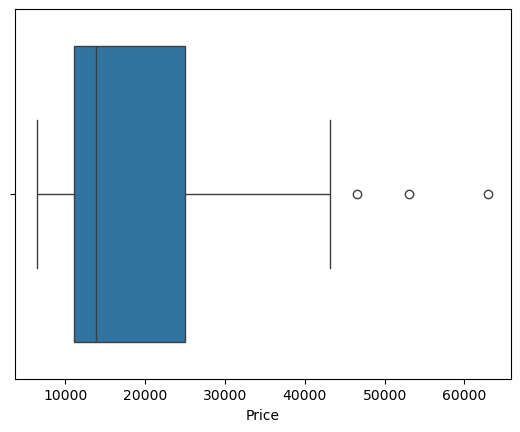

In [44]:
sns.boxplot(x=df['Price'])
plt.show()

In [43]:
df.groupby('Brand')['Price'].max().sort_values()

Brand
VW                                7399
Uniboom                           7699
TCL                               9490
Kenstar                           9990
FOXSKY                            9999
ONIDA                            12990
Midea                            14990
Voltas Beko                      14999
Godrej                           15490
Whirlpool                        20001
Voltas Beko by A Tata Product    20340
realme TechLife                  27490
MOTOROLA                         28090
Haier                            30570
BOSCH                            38790
Samsung                          46490
IFB                              52990
LG                               62990
Name: Price, dtype: int64

In [42]:
df1

Brand
VW                                7399
Uniboom                           7699
TCL                               9490
Kenstar                           9990
FOXSKY                            9999
ONIDA                            12990
Midea                            14990
Voltas Beko                      14999
Godrej                           15490
Whirlpool                        20001
Voltas Beko by A Tata Product    20340
realme TechLife                  27490
MOTOROLA                         28090
Haier                            30570
BOSCH                            38790
Samsung                          46490
IFB                              52990
LG                               62990
Name: Price, dtype: int64